BIKE SHARING RENTAL REGRESSION

EXPLORATORY DATA ANALYSIS

In [99]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [100]:
# Loading the Dataset
df=pd.read_csv('/content/Dataset.csv')
df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,31-12-2012,springer,2012,12,19,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,11,108,119
17375,17376,31-12-2012,springer,2012,12,20,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,8,81,89
17376,17377,31-12-2012,springer,2012,12,21,No,1,Working Day,Clear,?,0.2576,0.6,0.1642,7,83,90
17377,17378,31-12-2012,springer,2012,12,22,No,1,Working Day,Clear,0.26,0.2727,0.56,0.1343,13,48,61


In [101]:
# Shape of the Dataset
df.shape

(17379, 17)

In [102]:
# Size of the Dataset
df.size

295443

In [103]:
# Features in the Dataset
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [104]:
# Information of the Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   instant     17379 non-null  int64 
 1   dteday      17379 non-null  object
 2   season      17379 non-null  object
 3   yr          17379 non-null  object
 4   mnth        17379 non-null  object
 5   hr          17379 non-null  int64 
 6   holiday     17379 non-null  object
 7   weekday     17379 non-null  int64 
 8   workingday  17379 non-null  object
 9   weathersit  17379 non-null  object
 10  temp        17379 non-null  object
 11  atemp       17379 non-null  object
 12  hum         17379 non-null  object
 13  windspeed   17379 non-null  object
 14  casual      17379 non-null  object
 15  registered  17379 non-null  object
 16  cnt         17379 non-null  int64 
dtypes: int64(4), object(13)
memory usage: 2.3+ MB


In [105]:
# Measuring the central tendencies of numerical columns
df.describe()

,instant,hr,weekday,cnt
count,17379.0000000000,17379.0000000000,17379.0000000000,17379.0000000000
mean,8690.0000000000,11.5467518269,3.0036826054,189.4630876345
std,5017.0294996143,6.9144050953,2.0057714561,181.3875990919
min,1.0000000000,0.0000000000,0.0000000000,1.0000000000
25%,4345.5000000000,6.0000000000,1.0000000000,40.0000000000
50%,8690.0000000000,12.0000000000,3.0000000000,142.0000000000
75%,13034.5000000000,18.0000000000,5.0000000000,281.0000000000
max,17379.0000000000,23.0000000000,6.0000000000,977.0000000000


In [106]:
# Checking for null values
df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [107]:
# Count question-mark markers in each column
(df.astype(str) == "?").sum()

,0
instant,0
dteday,0
season,6
yr,1
mnth,1
hr,0
holiday,1
weekday,0
workingday,5
weathersit,4


In [108]:
# Identified a special symbol(?) in the data,which will cause inconsistency.
# Special symbol(?) is converted to null value for better imputation.
df.replace("?", np.nan, inplace=True)

print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (17379, 17)
Missing values:
 instant        0
dteday         0
season         6
yr             1
mnth           1
hr             0
holiday        1
weekday        0
workingday     5
weathersit     4
temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
cnt            0
dtype: int64
Duplicate rows: 0


In [109]:
# Checking for duplicates
df.duplicated().sum()

np.int64(0)

In [110]:
# Convert numeric columns stored as categorical columns
num_cols = [
    'temp', 'atemp', 'hum', 'windspeed',
    'casual', 'registered'
]

df[num_cols] = df[num_cols].apply(
    pd.to_numeric, errors='coerce'
)

# Fill missing numerical values with the median
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# Fill missing categorical values with the mode
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [111]:
# Understanding the type of the columns
print("Numerical columns:\n", df.select_dtypes(include='number').columns)
print("Categorical columns:\n", df.select_dtypes(include='object').columns)

Numerical columns:
 Index(['instant', 'hr', 'weekday', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')
Categorical columns:
 Index(['dteday', 'season', 'yr', 'mnth', 'holiday', 'workingday',
       'weathersit'],
      dtype='object')


In [112]:
# To know the start date and end dates of the dataset
print("Start Date:",min(df["dteday"]))
print("End Date:",max(df["dteday"]))

Start Date: 01-01-2011
End Date: 31-12-2012


In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  object 
 3   yr          17379 non-null  object 
 4   mnth        17379 non-null  object 
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  object 
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  object 
 9   weathersit  17379 non-null  object 
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  float64
 15  registered  17379 non-null  float64
 16  cnt         17379 non-null  int64  
dtypes: float64(6), int64(4), object(7)
memory usage: 2.3+ MB


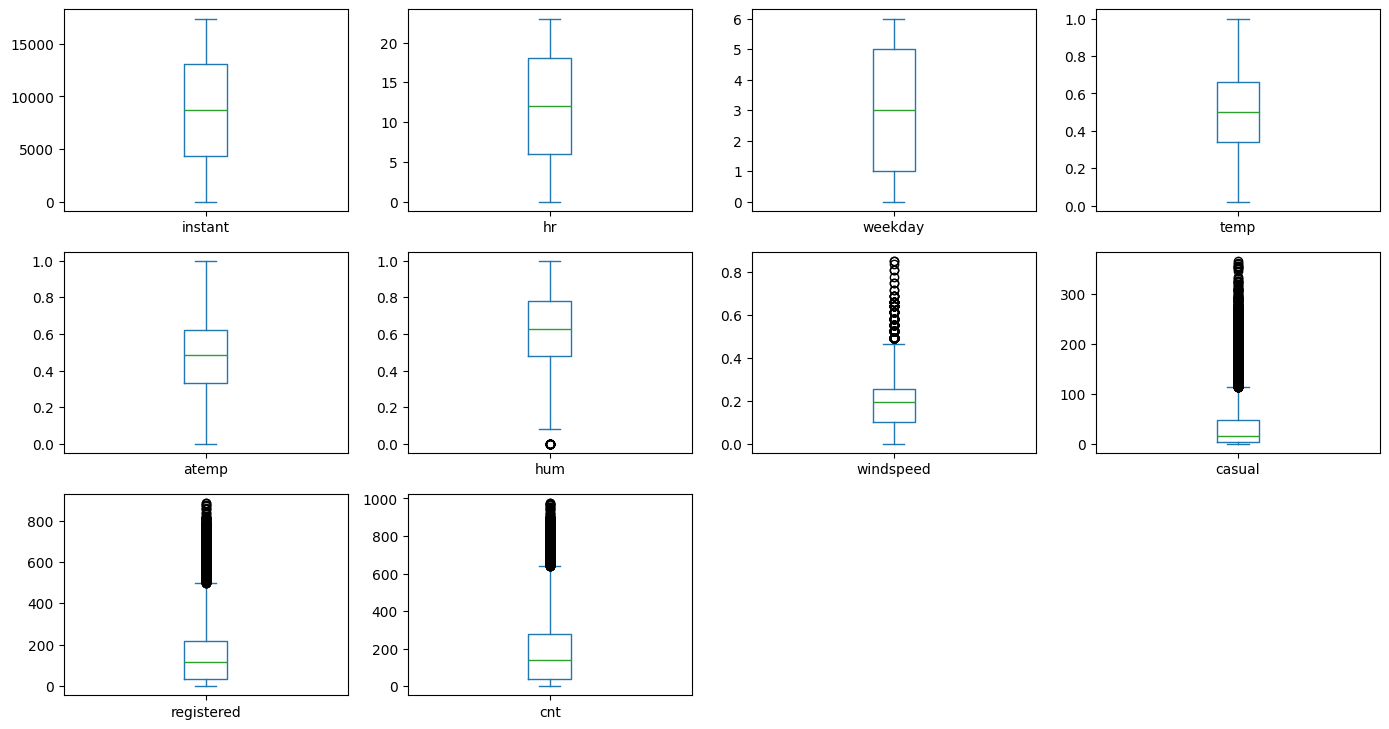

In [114]:
# Using Boxplot for the outlier detection
num_cols = df.select_dtypes(include='number').columns

df[num_cols].plot(
    kind='box', subplots=True,
    layout=(5, 4), figsize=(14, 12),
    sharex=False, sharey=False
)

plt.tight_layout()
plt.show()

In [115]:
# Outlier capping for better consistency
for col in ['temp', 'atemp', 'hum', 'windspeed', 'cnt']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outliers = df[col][
        (df[col] < q1 - 1.5 * iqr) |
        (df[col] > q3 + 1.5 * iqr)
    ]

    print(col, "potential outliers:", len(outliers))

temp potential outliers: 0
atemp potential outliers: 0
hum potential outliers: 22
windspeed potential outliers: 341
cnt potential outliers: 505


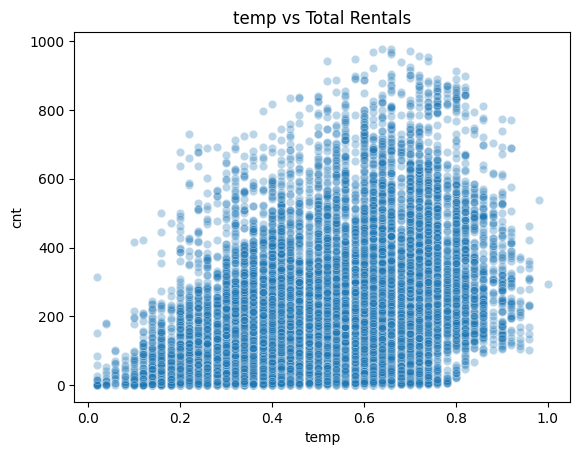

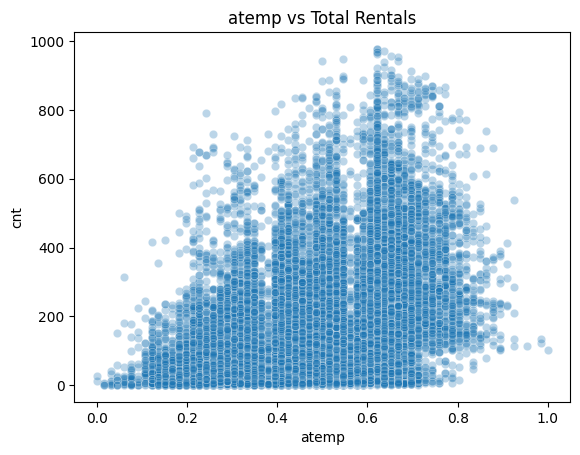

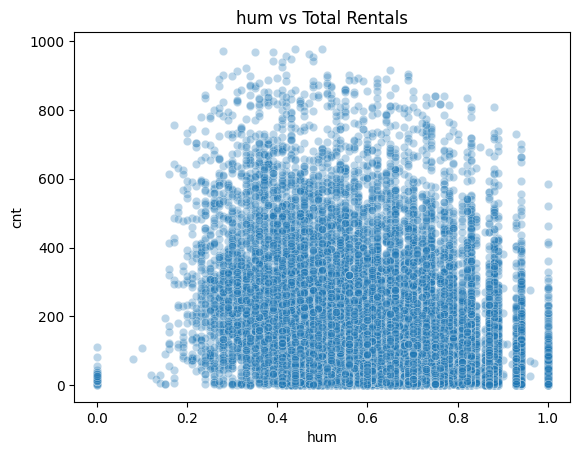

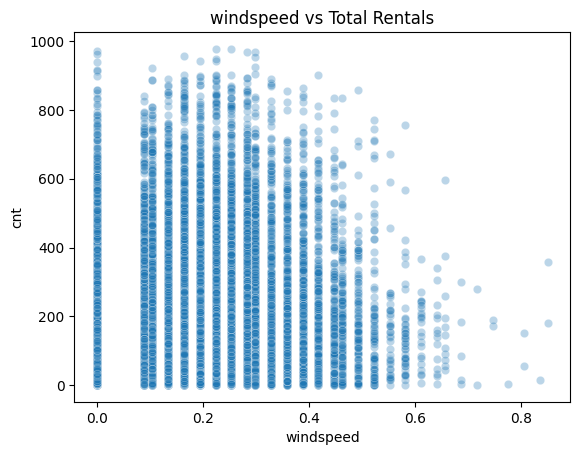

In [116]:
# Understanding the total rentals in various conditions
for col in ['temp', 'atemp', 'hum', 'windspeed']:
    sns.scatterplot(data=df, x=col, y='cnt', alpha=0.3)
    plt.title(f'{col} vs Total Rentals')
    plt.show()

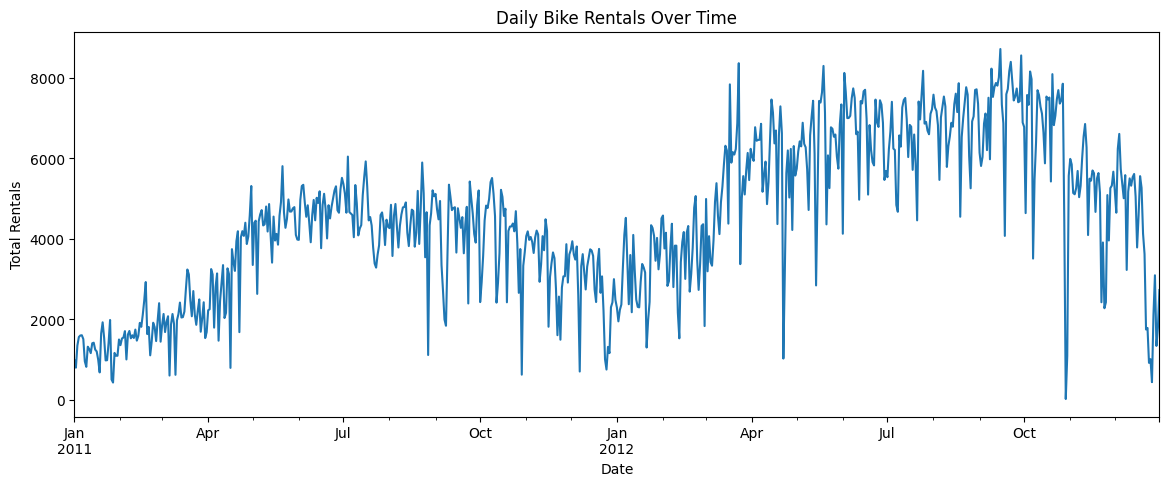

In [117]:
# Bike rentals over the years as per dataset
df['dteday'] = pd.to_datetime(
    df['dteday'], dayfirst=True, errors='coerce'
)

daily = df.groupby('dteday')['cnt'].sum()

daily.plot(figsize=(14, 5))
plt.title('Daily Bike Rentals Over Time')
plt.xlabel('Date')
plt.ylabel('Total Rentals')
plt.show()

• The graph indicates that the bike rental was a bit low in previous years but as the time is passing by the demand is conistently growing.

• It shows the demand may vary in various years but the demand will only increase as the time is passing by and observe the fluctuations in the graph which supports our assumption.

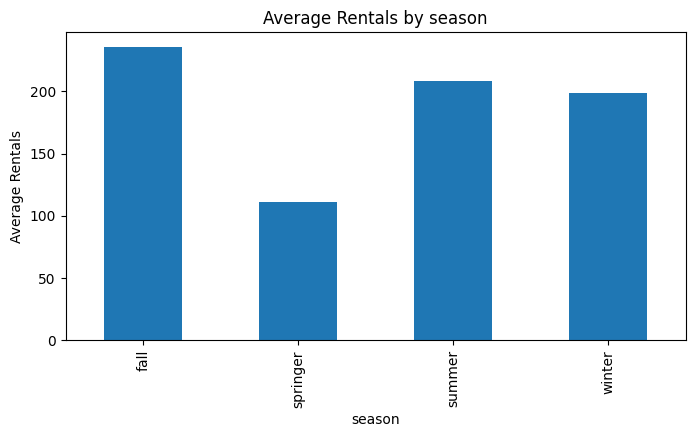

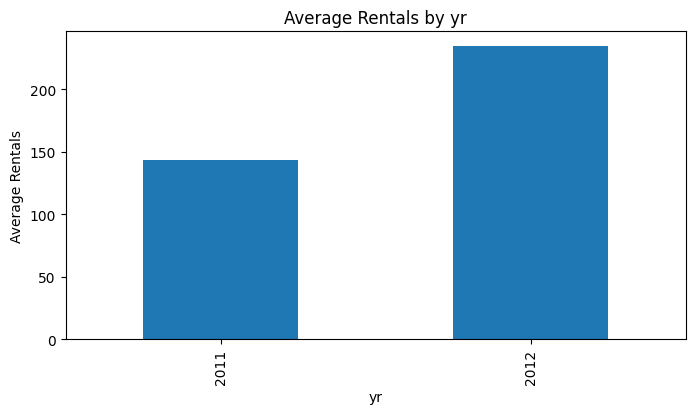

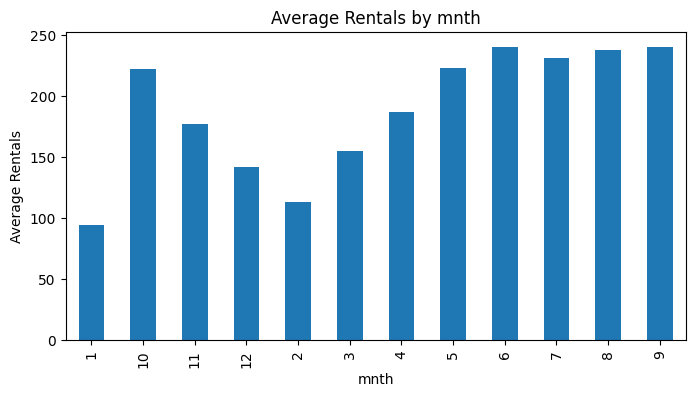

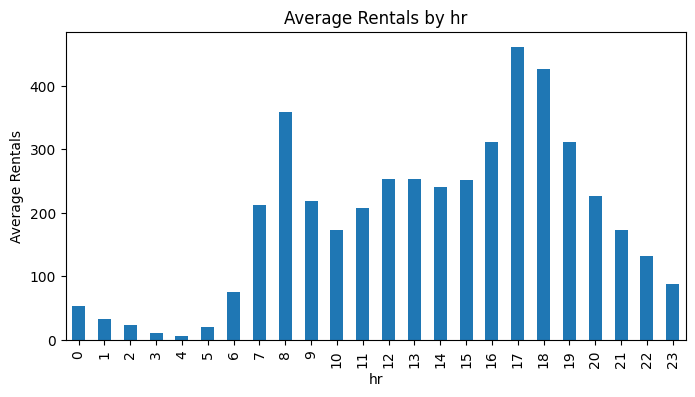

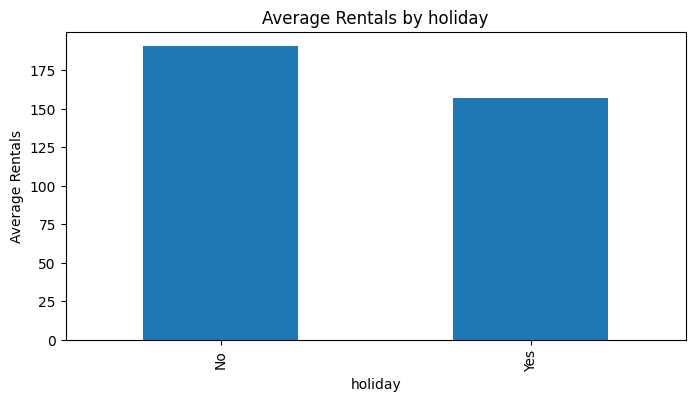

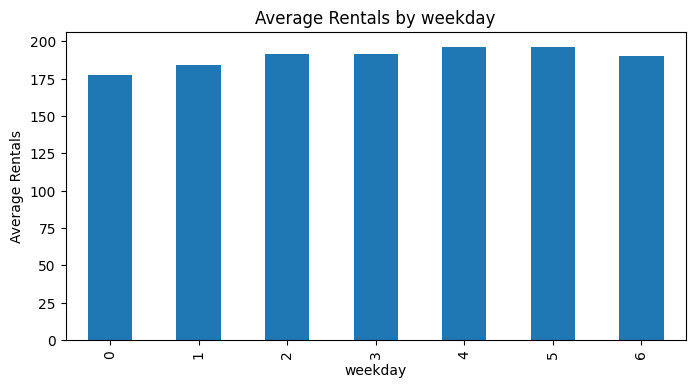

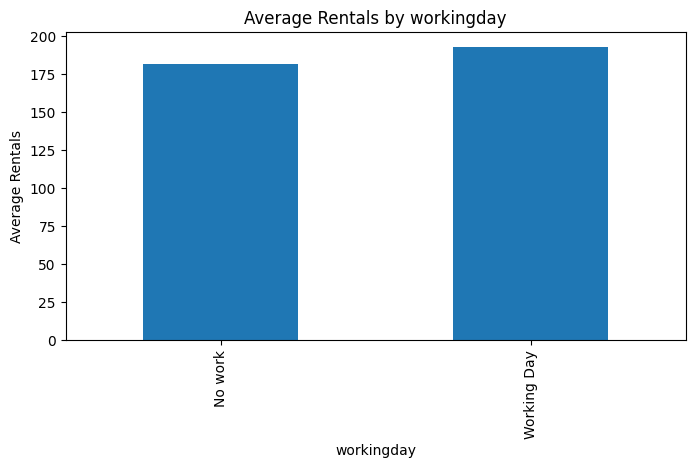

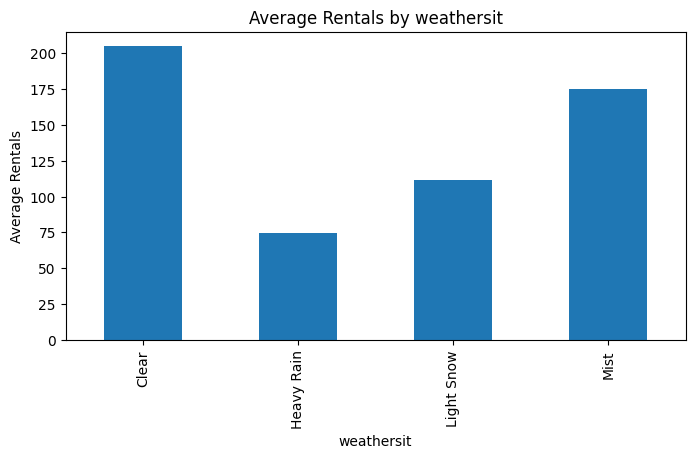

In [118]:
# Measuring the average rentals considering various aspects
for col in ['season', 'yr', 'mnth','hr','holiday','weekday','workingday','weathersit']:
    df.groupby(col)['cnt'].mean().plot(kind='bar', figsize=(8, 4))
    plt.title(f'Average Rentals by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Rentals')
    plt.show()

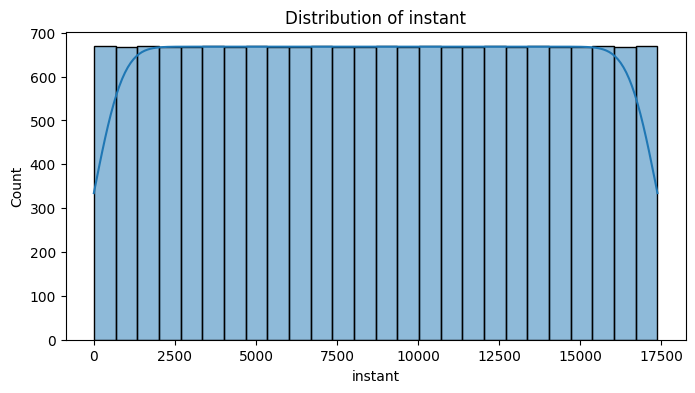

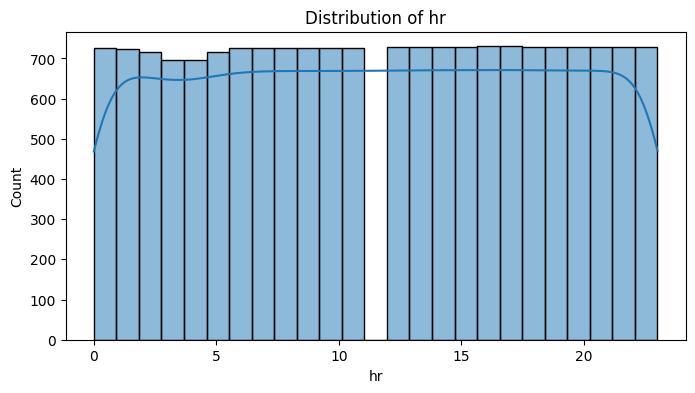

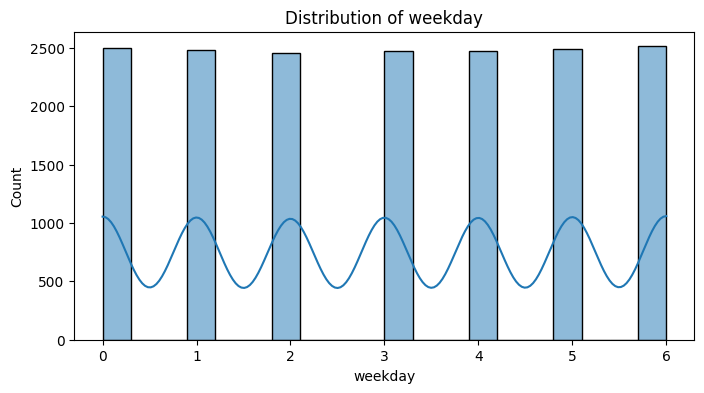

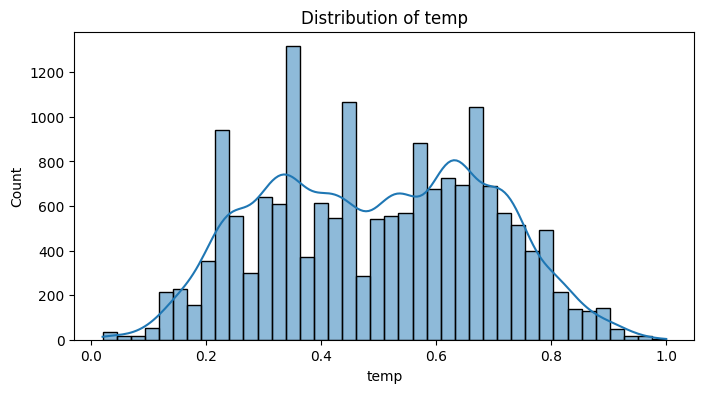

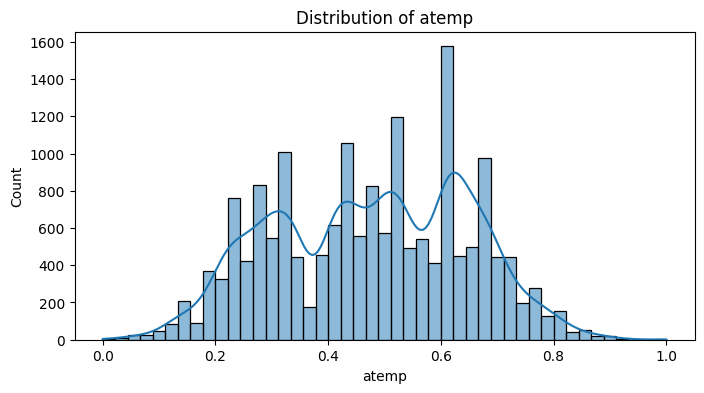

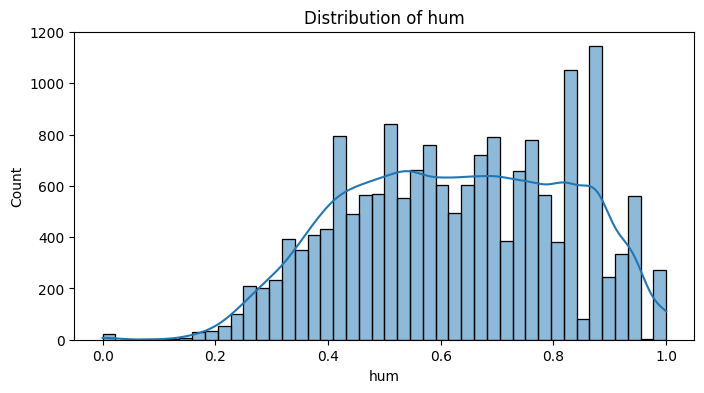

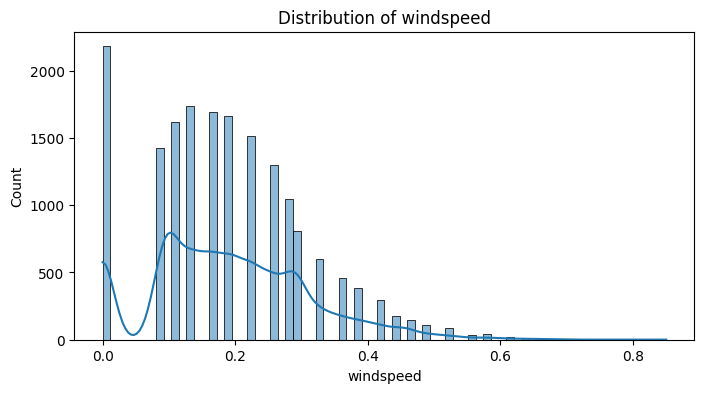

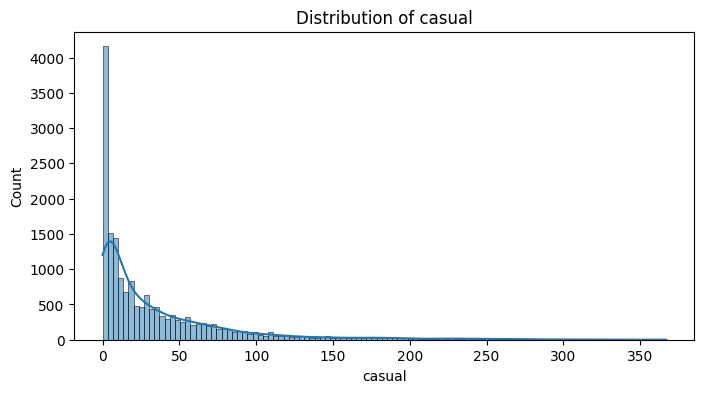

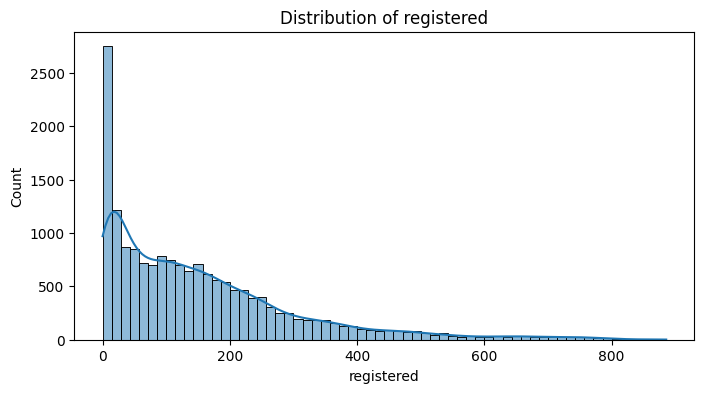

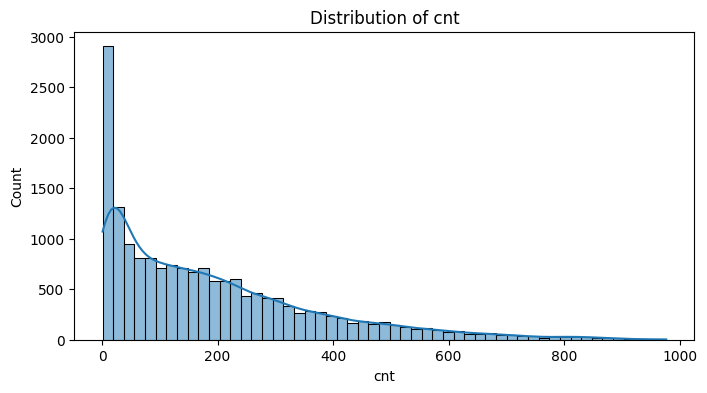

In [119]:
# To understand the distribution of variou aspects
for col in df.select_dtypes(include='number').columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')

By observing the graphs we can conclude that the surrounding nature and atmosphere also plays a major role in the bike rentals because if the temperature is high then there will be very few rentals but at a comfortable temperature there is a chance of better demands.

And it also proves the seasons,months and weekdays and etc are the various factors which affect the demand for rentals as prefered by the people and their necissities.

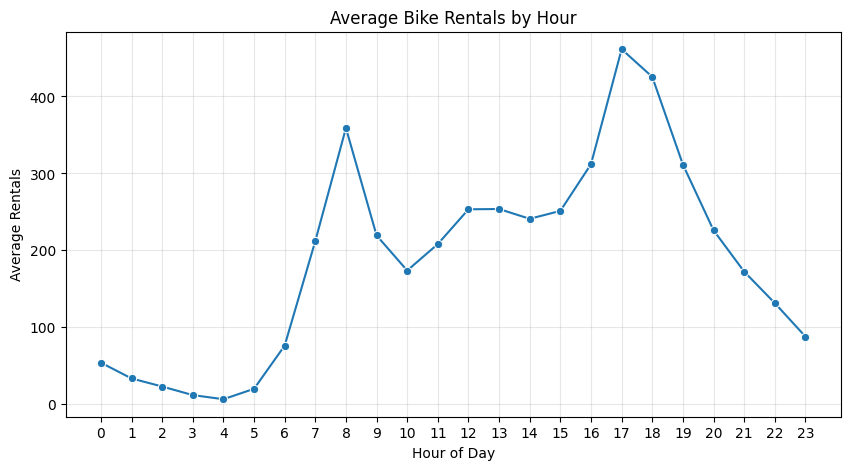

In [120]:
# Average bike rentals by hours
plt.figure(figsize=(10, 5))

sns.lineplot(data=df, x='hr', y='cnt', errorbar=None,marker='o')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Rentals')
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

Key Findings :

By this graph we can assume that time of day greatly affect's the bike rentals and their demand.
1. Lowest rentals during early morning: Bike rentals are at their lowest between 3:00 AM and 5:00 AM, with the minimum around 4:00 AM.
2. Morning peak: Rentals rise sharply from 6:00 AM and reach a local peak of approximately 370 rentals at 8:00 AM, before declining at 9:00–10:00 AM.
3. Stable midday demand: From 11:00 AM to 3:00 PM, rentals remain relatively steady at around 220–270 per hour.
4. Highest evening demand: The maximum occurs at 5:00 PM (17:00), with approximately 490 rentals, followed by about 450 rentals at 6:00 PM.
5. Declining nighttime demand: After 6:00 PM, rentals decrease steadily, reaching approximately 110 by 11:00 PM.

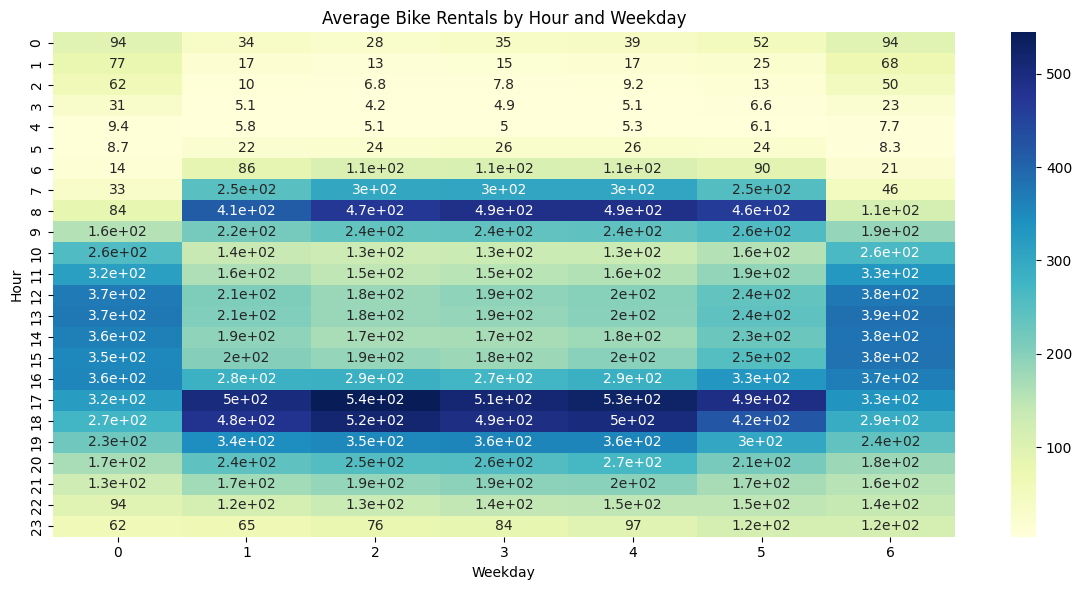

In [121]:
# Heatmap for Average Bike Rentals by hours and weekdays
plt.figure(figsize=(12, 6))

hour_day = df.pivot_table(
    values='cnt',
    index='hr',
    columns='weekday',
    aggfunc='mean'
)

sns.heatmap(hour_day, cmap='YlGnBu',annot=True)

plt.title('Average Bike Rentals by Hour and Weekday')
plt.xlabel('Weekday')
plt.ylabel('Hour')
plt.tight_layout()
plt.show()

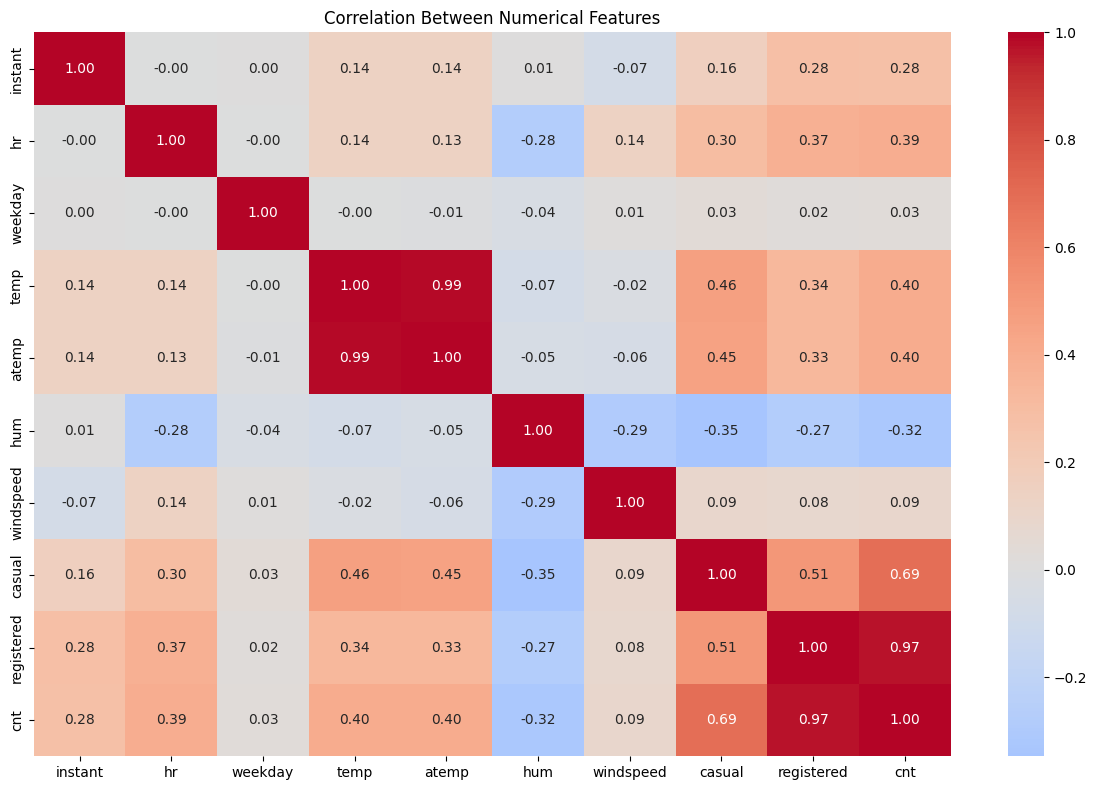

In [122]:
# To understand the corelation between the features
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True, cmap='coolwarm',
    fmt='.2f', center=0
)

plt.title('Correlation Between Numerical Features')
plt.tight_layout()
plt.show()

In [123]:
# Arranging data in a proper order and splitting it into train and test split
df = df.sort_values("dteday").reset_index(drop=True)

last_date = df["dteday"].max()

test_start = last_date - pd.DateOffset(years=1)

train_df = df[df["dteday"] < test_start].copy()
test_df = df[df["dteday"] >= test_start].copy()

print("Training period:")
print(train_df["dteday"].min(), "to", train_df["dteday"].max())

print("\nTesting period:")
print(test_df["dteday"].min(), "to", test_df["dteday"].max())

print("\nTrain rows:", len(train_df))
print("Test rows :", len(test_df))

Training period:
2011-01-01 00:00:00 to 2011-12-30 00:00:00

Testing period:
2011-12-31 00:00:00 to 2012-12-31 00:00:00

Train rows: 8621
Test rows : 8758


In [124]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np

# Define the high-precision categorical features to encode
categorical_cols = ["season", "yr", "mnth", "holiday", "workingday", "weathersit"]

train_encoded = train_df.copy()
test_encoded = test_df.copy()

# Standard LabelEncoder dictionary to hold encoders for each column
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    # Fit on training data
    train_encoded[col] = le.fit_transform(train_df[col].astype(str))
    encoders[col] = le

    # Safeguard test set against unseen classes
    # Map unseen categories to a fallback value if they appear in the test set
    test_categories = test_df[col].astype(str)
    known_classes = set(le.classes_)

    # Temporarily replace unseen test items with the first known class to prevent errors,
    # then transform, or keep original mapping if all are known.
    safe_test_categories = test_categories.map(lambda x: x if x in known_classes else le.classes_[0])
    test_encoded[col] = le.transform(safe_test_categories)

# Select numerical model features (excluding 'dteday' and target 'cnt')
model_features = [col for col in train_encoded.columns if col not in ["dteday", "cnt"]]

X_train = train_encoded[model_features]
y_train = train_encoded["cnt"]

X_test = test_encoded[model_features]
y_test = test_encoded["cnt"]

print("Train shape (Label Encoded):", X_train.shape)
print("Test shape (Label Encoded):", X_test.shape)

Train shape (Label Encoded): (8621, 15)
Test shape (Label Encoded): (8758, 15)


MODEL BUILDING AND MODEL EVALUATION

In [125]:
# EVALUATION FUNCTION
# Before training models, create one common evaluation function.
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

def evaluate_model(name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mape = np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100

    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2
    }
results = []

MODEL-1 : DECISION TREE

In [126]:
#Training and evaluating decision tree model
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=25,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

# Exclude 'dteday' from the training and testing sets as it is a datetime column
# and cannot be directly parsed by scikit-learn models
X_train_numeric = X_train.drop(columns=['dteday'], errors='ignore')
X_test_numeric = X_test.drop(columns=['dteday'], errors='ignore')

dt_model.fit(X_train_numeric, y_train)

#Predict
dt_pred = dt_model.predict(X_test_numeric)

#Evaluate
dt_result = evaluate_model(
    "Decision Tree",
    y_test,
    dt_pred
)

results.append(dt_result)

dt_result

{'Model': 'Decision Tree',
 'MAE': 13.985384791048185,
 'RMSE': np.float64(42.01674869128848),
 'MAPE': np.float64(2.7724228677067155),
 'R2': 0.9595019819742721}

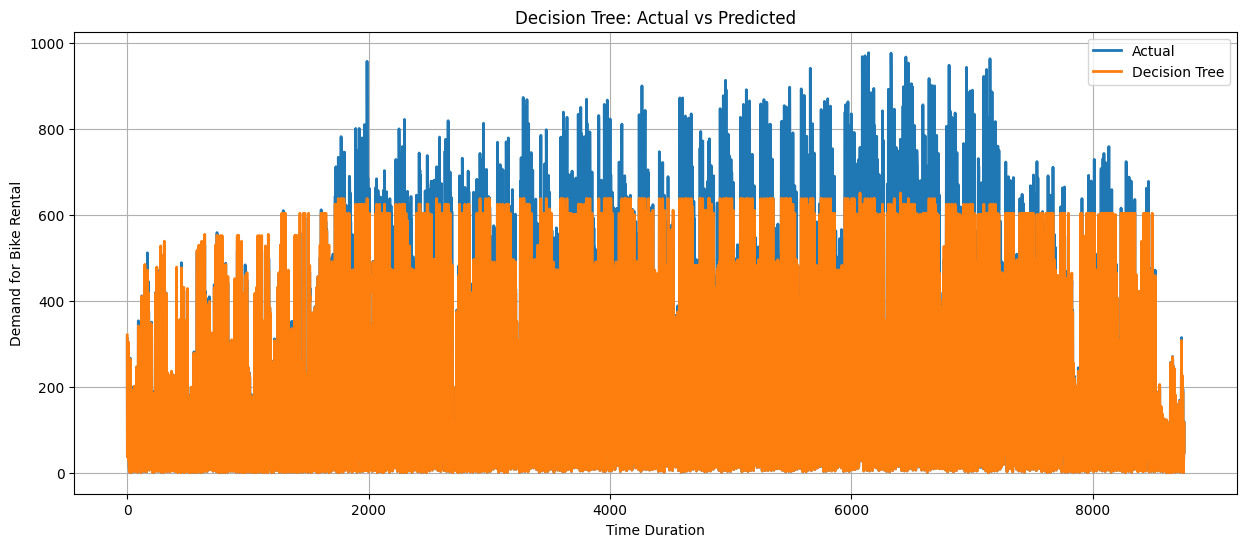

In [127]:
#Plot actual vs predicted
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.values,
    label="Actual",
    linewidth=2
)

plt.plot(
    dt_pred,
    label="Decision Tree",
    linewidth=2
)

plt.title("Decision Tree: Actual vs Predicted")
plt.xlabel("Time Duration")
plt.ylabel("Demand for Bike Rental")
plt.legend()
plt.grid(True)
plt.show()

MODEL-2 : RANDOM FOREST

In [128]:
#Training and evaluating random forest model
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=25,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Exclude 'dteday' from the training and testing sets as it is a datetime column
# and cannot be directly parsed by scikit-learn models
X_train_numeric = X_train.drop(columns=['dteday'], errors='ignore')
X_test_numeric = X_test.drop(columns=['dteday'], errors='ignore')

rf_model.fit(X_train_numeric, y_train)

#Predict
rf_pred = rf_model.predict(X_test_numeric)

#Evaluate
rf_result = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)

results.append(rf_result)

rf_result

{'Model': 'Random Forest',
 'MAE': 13.314481616807491,
 'RMSE': np.float64(44.132925049797194),
 'MAPE': np.float64(2.250669712003349),
 'R2': 0.9553198823094284}

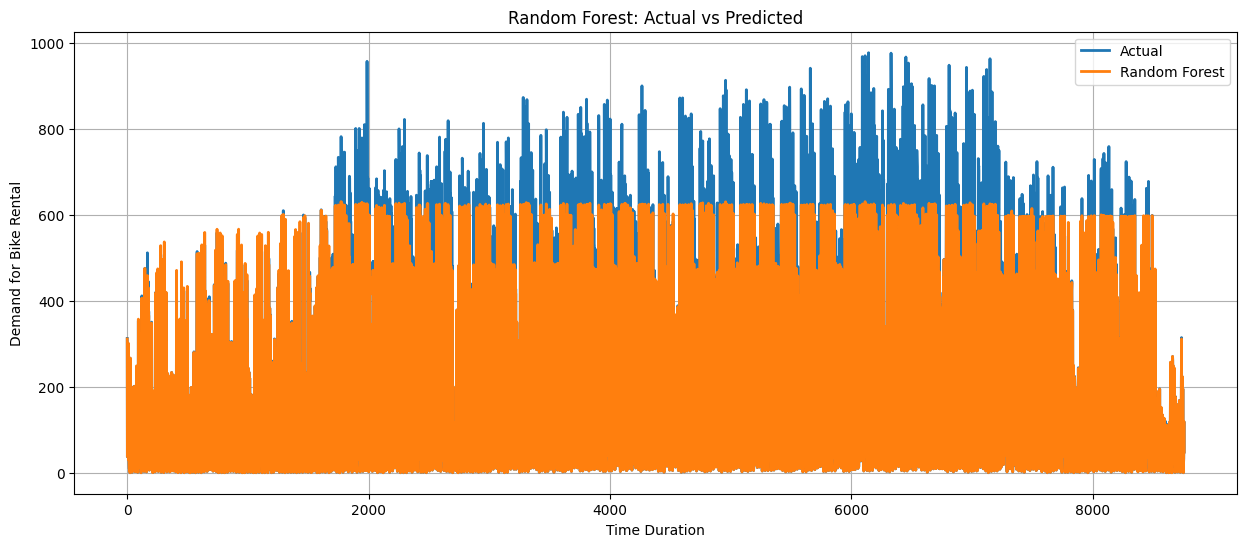

In [129]:
#Plot actual vs predicted
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.values,
    label="Actual",
    linewidth=2
)

plt.plot(
    rf_pred,
    label="Random Forest",
    linewidth=2
)

plt.title("Random Forest: Actual vs Predicted")
plt.xlabel("Time Duration")
plt.ylabel("Demand for Bike Rental")
plt.legend()
plt.grid(True)
plt.show()

MODEL-3 : XGBOOST

In [130]:
from xgboost import XGBRegressor

#Train
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Drop datetime column 'dteday' to avoid ValueError
X_train_numeric = X_train.drop(columns=['dteday'], errors='ignore')
X_test_numeric = X_test.drop(columns=['dteday'], errors='ignore')

xgb_model.fit(
    X_train_numeric,
    y_train
)

#Predict
xgb_pred = xgb_model.predict(X_test_numeric)

#Evaluate
xgb_result = evaluate_model(
    "XGBoost",
    y_test,
    xgb_pred
)

results.append(xgb_result)

xgb_result

{'Model': 'XGBoost',
 'MAE': 18.942649841308594,
 'RMSE': np.float64(49.787801671820176),
 'MAPE': np.float64(6.148408066062542),
 'R2': 0.9431363344192505}

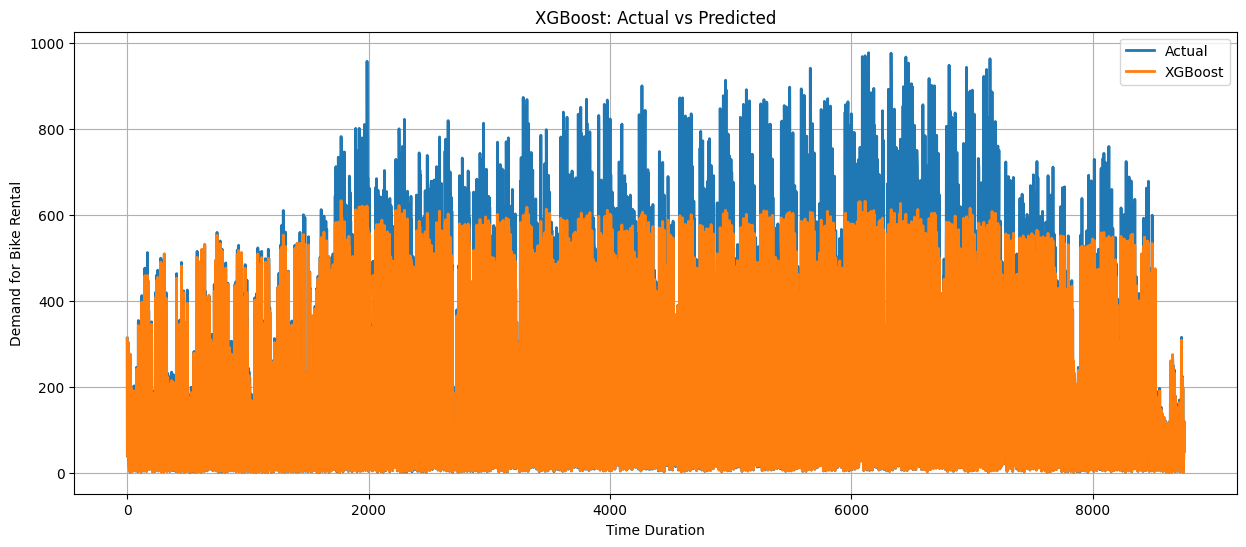

In [131]:
#Plot actual vs predicted
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.values,
    label="Actual",
    linewidth=2
)

plt.plot(
    xgb_pred,
    label="XGBoost",
    linewidth=2
)

plt.title("XGBoost: Actual vs Predicted")
plt.xlabel("Time Duration")
plt.ylabel("Demand for Bike Rental")
plt.legend()
plt.grid(True)
plt.show()

MODEL-4 : GRADIENT BOOSTING

In [132]:
from sklearn.ensemble import GradientBoostingRegressor

#Train
gbr_model = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.8,
    max_features=0.8,
    random_state=50
)

# Drop datetime column 'dteday' to avoid ValueError
X_train_numeric = X_train.drop(columns=['dteday'], errors='ignore')
X_test_numeric = X_test.drop(columns=['dteday'], errors='ignore')

gbr_model.fit(
    X_train_numeric,
    y_train
)

#Predict
gbr_pred = gbr_model.predict(X_test_numeric)

#Evaluate
gbr_result = evaluate_model(
    "Gradient Boosting",
    y_test,
    gbr_pred
)

results.append(gbr_result)

gbr_result

{'Model': 'Gradient Boosting',
 'MAE': 12.428224431306113,
 'RMSE': np.float64(41.665790722821235),
 'MAPE': np.float64(2.9756958190098994),
 'R2': 0.9601757010455885}

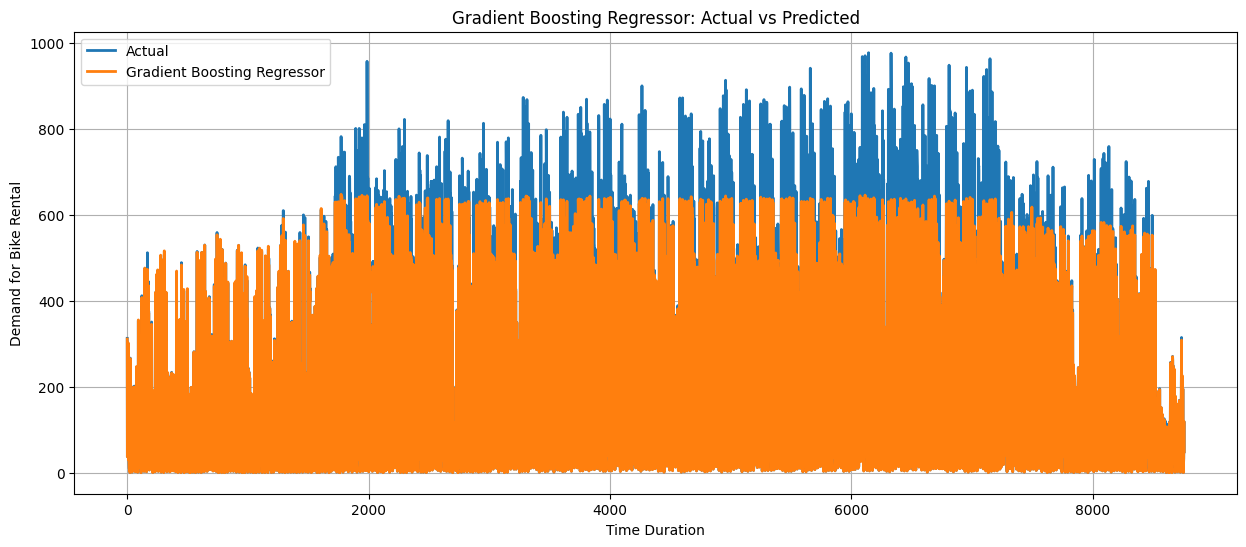

In [134]:
#Plot actual vs predicted
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.values,
    label="Actual",
    linewidth=2
)

plt.plot(
    gbr_pred,
    label="Gradient Boosting Regressor",
    linewidth=2
)

plt.title("Gradient Boosting Regressor: Actual vs Predicted")
plt.xlabel("Time Duration")
plt.ylabel("Demand for Bike Rental")
plt.legend()
plt.grid(True)
plt.show()

In [135]:
gbr_pred

array([311.31880831,  37.51802872,  51.71330821, ...,  61.40762399,
       119.89065639,  49.53692766])

MODEL-5 : RNN

In [136]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Exclude 'dteday' to ensure all elements are numeric
X_train_clean = X_train.drop(columns=['dteday'], errors='ignore')
X_test_clean = X_test.drop(columns=['dteday'], errors='ignore')

# Scale the features and target to range [0, 1] for neural network stability
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_clean)
X_test_scaled = scaler_X.transform(X_test_clean)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).flatten()

# Create sequences
time_steps = 24

X_train_rnn = []
y_train_rnn = []

for i in range(time_steps, len(X_train_scaled)):
    X_train_rnn.append(X_train_scaled[i-time_steps:i])
    y_train_rnn.append(y_train_scaled[i])

X_test_rnn = []
y_test_rnn = []

for i in range(time_steps, len(X_test_scaled)):
    X_test_rnn.append(X_test_scaled[i-time_steps:i])
    y_test_rnn.append(y_test_scaled[i])

X_train_rnn = np.array(X_train_rnn).astype('float32')
y_train_rnn = np.array(y_train_rnn).astype('float32')

X_test_rnn = np.array(X_test_rnn).astype('float32')
y_test_rnn = np.array(y_test_rnn).astype('float32')

# Build recurrent network using SimpleRNN only
rnn_model = Sequential([
    SimpleRNN(
        128,
        activation="tanh",
        return_sequences=True,
        input_shape=(X_train_rnn.shape[1], X_train_rnn.shape[2])
    ),
    Dropout(0.2),
    SimpleRNN(
        64,
        activation="tanh"
    ),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

# Compile
rnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

# Train
rnn_model.fit(
    X_train_rnn,
    y_train_rnn,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

# Predict and inverse transform to actual scale"""
rnn_pred_scaled = rnn_model.predict(X_test_rnn).flatten()
rnn_pred = scaler_y.inverse_transform(rnn_pred_scaled.reshape(-1, 1)).flatten()

# Re-align targets on original unscaled domain
y_test_rnn_unscaled = scaler_y.inverse_transform(y_test_rnn.reshape(-1, 1)).flatten()

# Evaluate
rnn_result = evaluate_model(
    "RNN",
    y_test_rnn_unscaled,
    rnn_pred
)

# Remove any previous 'RNN' results to avoid duplicates
results = [r for r in results if r['Model'] != 'RNN']
results.append(rnn_result)
rnn_result

Epoch 1/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0581 - val_loss: 0.0248
Epoch 2/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0302 - val_loss: 0.0212
Epoch 3/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0266 - val_loss: 0.0243
Epoch 4/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0241 - val_loss: 0.0176
Epoch 5/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0219 - val_loss: 0.0168
Epoch 6/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0206 - val_loss: 0.0366
Epoch 7/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 0.0199 - val_loss: 0.0161
Epoch 8/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0191 - val_loss: 0.0180
Epoch 9/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0177 - val_loss: 0.0148
Epoch 10/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0174 - val_loss: 0.0153
Epoch 11/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 0.0166 - val_loss: 0.0148
Epoch 12/20
121/121 ━━━━━━━━━━━━━━━━━━━━ 

{'Model': 'RNN',
 'MAE': 112.8155746459961,
 'RMSE': np.float64(159.7044878439551),
 'MAPE': np.float32(201.82214),
 'R2': 0.41553086042404175}

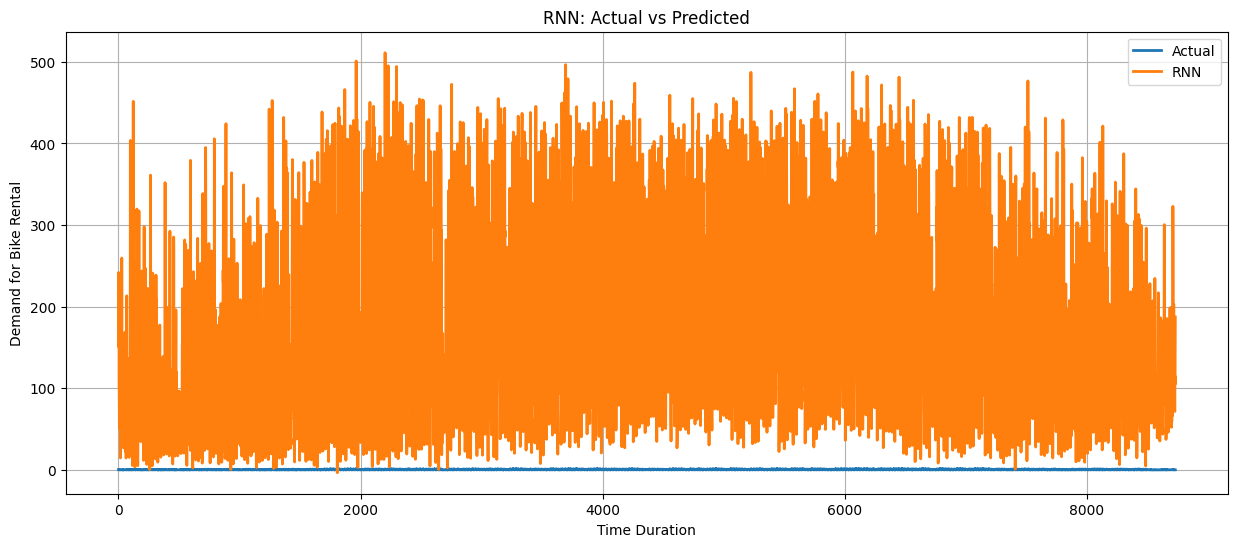

In [137]:
#Plot actual vs predicted
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_rnn,
    label="Actual",
    linewidth=2
)

plt.plot(
    rnn_pred,
    label="RNN",
    linewidth=2
)

plt.title("RNN: Actual vs Predicted")
plt.xlabel("Time Duration")
plt.ylabel("Demand for Bike Rental")
plt.legend()
plt.grid(True)
plt.show()

MODEL-6 : LSTM

In [138]:
# importing necessary libraries for this certain model
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [139]:
#LSTM preprocessing
scaler = MinMaxScaler()

# Training the df
train_values = df["cnt"].values.reshape(-1, 1)

scaled_train = scaler.fit_transform(
    train_values
)
LOOKBACK = 168

#Function:
def create_sequences(data, lookback):

    X = []
    y = []

    for i in range(lookback, len(data)):

        X.append(
            data[i-lookback:i, 0]
        )

        y.append(
            data[i, 0]
        )

    X = np.array(X)
    y = np.array(y)

    return X, y

X_lstm_train, y_lstm_train = create_sequences(
    scaled_train,
    LOOKBACK
)

X_lstm_train = X_lstm_train.reshape(
    X_lstm_train.shape[0],
    X_lstm_train.shape[1],
    1
)

In [140]:
#Build the LSTM
lstm_model = Sequential([
    LSTM(32, return_sequences=True, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(16),
    Dropout(0.2),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop],
    shuffle=False
)

Epoch 1/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 23s 165ms/step - loss: 0.0274 - val_loss: 0.0442
Epoch 2/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 19s 153ms/step - loss: 0.0292 - val_loss: 0.0328
Epoch 3/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 20s 167ms/step - loss: 0.0261 - val_loss: 0.0301
Epoch 4/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 19s 153ms/step - loss: 0.0252 - val_loss: 0.0289
Epoch 5/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 20s 160ms/step - loss: 0.0240 - val_loss: 0.0285
Epoch 6/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 22s 182ms/step - loss: 0.0230 - val_loss: 0.0270
Epoch 7/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 20s 165ms/step - loss: 0.0219 - val_loss: 0.0274
Epoch 8/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 19s 154ms/step - loss: 0.0214 - val_loss: 0.0260
Epoch 9/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 19s 154ms/step - loss: 0.0210 - val_loss: 0.0265
Epoch 10/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 20s 166ms/step - loss: 0.0208 - val_loss: 0.0241
Epoch 11/20
122/122 ━━━━━━━━━━━━━━━━━━━━ 19s 152ms/step - loss: 0.0200 - val_loss: 0.0242
Epoch 12/20
122/122

In [141]:
#LSTM test prediction
# Since we do not have train_df/test_df, we use the complete sequence from df['cnt']
combined_values = df["cnt"].values.reshape(-1, 1)

combined_scaled = scaler.transform(
    combined_values
)

In [142]:
# Calculate the split point matching our 80/20 train/test split ratio chronologically
test_start_index = int(len(df) * 0.8)
lstm_inputs = combined_scaled[
    test_start_index - LOOKBACK:
]

X_lstm_test = []

for i in range(
    LOOKBACK,
    len(lstm_inputs)
):
    X_lstm_test.append(
        lstm_inputs[i-LOOKBACK:i, 0]
    )

X_lstm_test = np.array(X_lstm_test)

X_lstm_test = X_lstm_test.reshape(
    X_lstm_test.shape[0],
    X_lstm_test.shape[1],
    1
)

# Predict
lstm_pred_scaled = lstm_model.predict(
    X_lstm_test
)

# Convert back: inverse the scaling to get actual counts
lstm_pred = scaler.inverse_transform(lstm_pred_scaled).flatten()

# Evaluate
y_lstm_test = df["cnt"].values[test_start_index:]

lstm_result = evaluate_model(
    "LSTM",
    y_lstm_test,
    lstm_pred
)

results.append(lstm_result)

lstm_result

109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step


{'Model': 'LSTM',
 'MAE': 125.23800659179688,
 'RMSE': np.float64(165.6387730122389),
 'MAPE': np.float64(274.54937024404586),
 'R2': 0.43448805809020996}

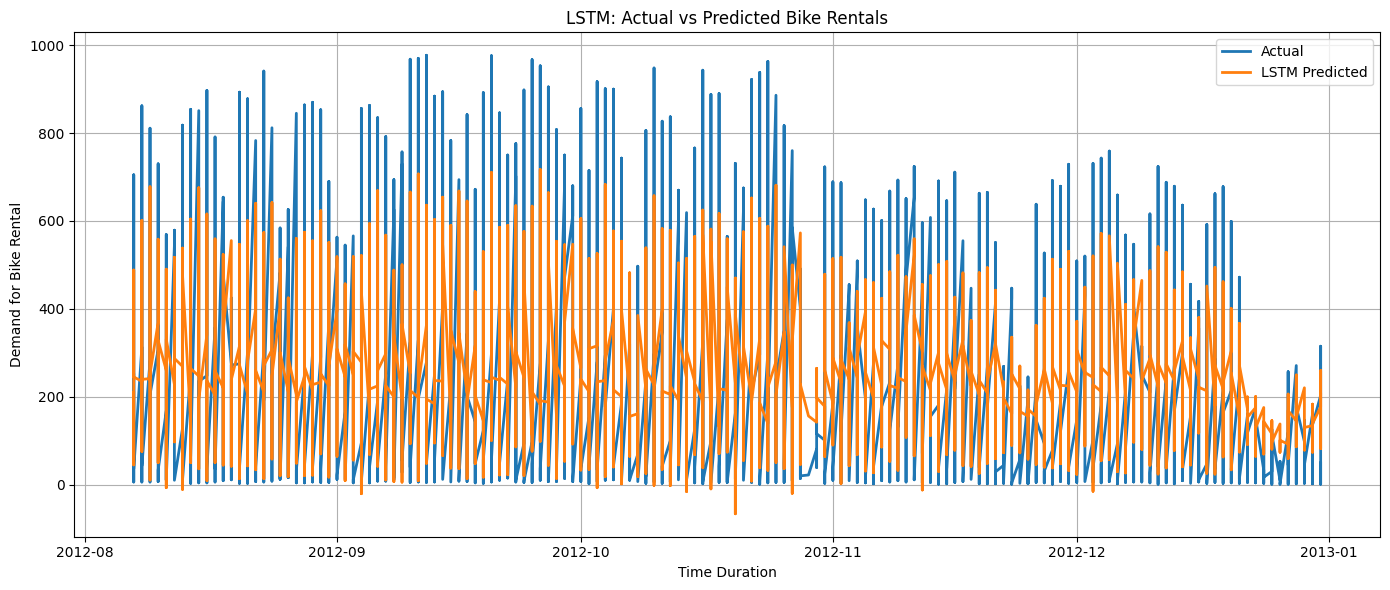

In [143]:
#Plot actual vs predicted
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Generate a matching time axis or index for the test portion
test_dates = df["dteday"].iloc[test_start_index:].values if "dteday" in df.columns else range(len(y_lstm_test))

plt.plot(
    test_dates,
    y_lstm_test,
    label="Actual",
    linewidth=2
)

plt.plot(
    test_dates,
    lstm_pred,
    label="LSTM Predicted",
    linewidth=2
)

plt.title("LSTM: Actual vs Predicted Bike Rentals")
plt.xlabel("Time Duration")
plt.ylabel("Demand for Bike Rental")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [144]:
#Create final model comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

results_df

,Model,MAE,RMSE,MAPE,R2
0,Gradient Boosting,12.4282244313,41.6657907228,2.9756958190,0.9601757010
1,Decision Tree,13.9853847910,42.0167486913,2.7724228677,0.9595019820
2,Random Forest,13.3144816168,44.1329250498,2.2506697120,0.9553198823
3,XGBoost,18.9426498413,49.7878016718,6.1484080661,0.9431363344
4,RNN,112.8155746460,159.7044878440,201.8221435547,0.4155308604
5,LSTM,125.2380065918,165.6387730122,274.5493702440,0.4344880581


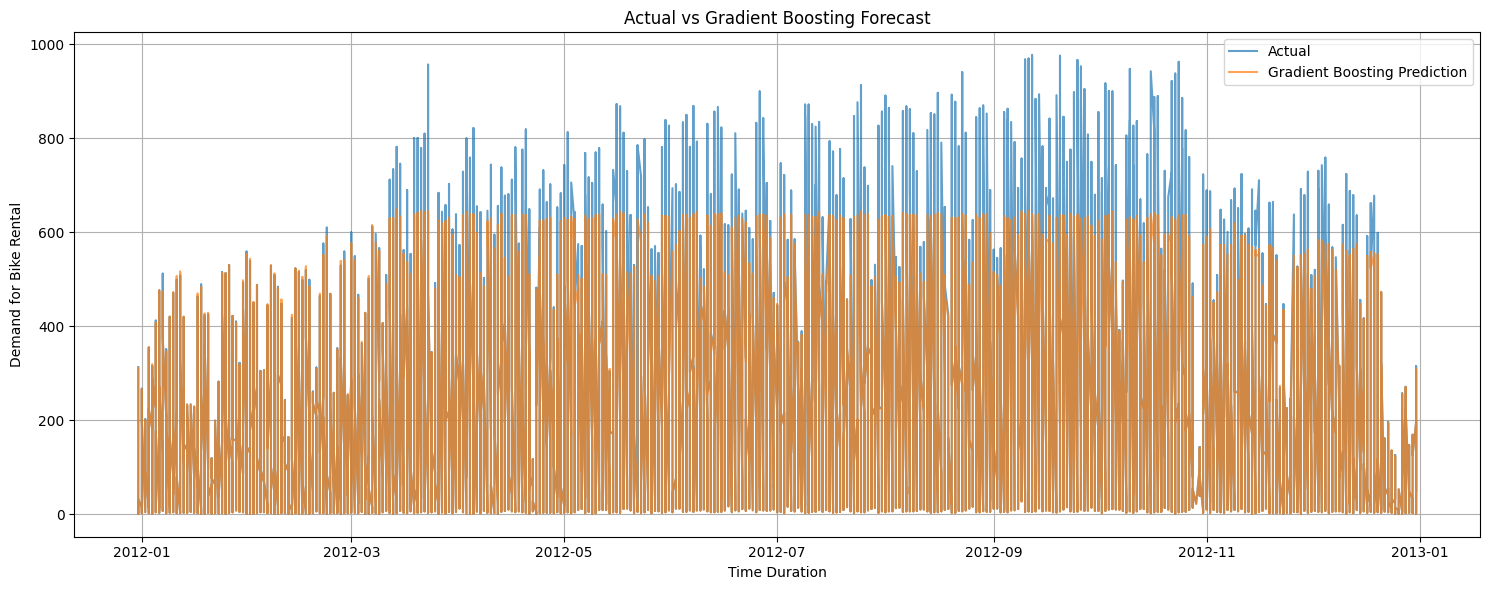

In [145]:
# Best Model's Plot actual vs predicted
# Since we do not have 'test_df', we align dates using the index of X_test from the main 'df'
test_dates = df.loc[X_test.index, "dteday"] if "dteday" in df.columns else range(len(y_test))

# Sort by date index for a cleaner line plot visualization
sort_idx = np.argsort(test_dates)

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates.iloc[sort_idx],
    y_test.iloc[sort_idx],
    label="Actual",
    alpha=0.7
)

plt.plot(
    test_dates.iloc[sort_idx],
    gbr_pred[sort_idx],
    label="Gradient Boosting Prediction",
    alpha=0.7
)

plt.xlabel("Time Duration")
plt.ylabel("Demand for Bike Rental")
plt.title("Actual vs Gradient Boosting Forecast")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [146]:
best_pred = gbr_pred
residuals = y_test.values - best_pred

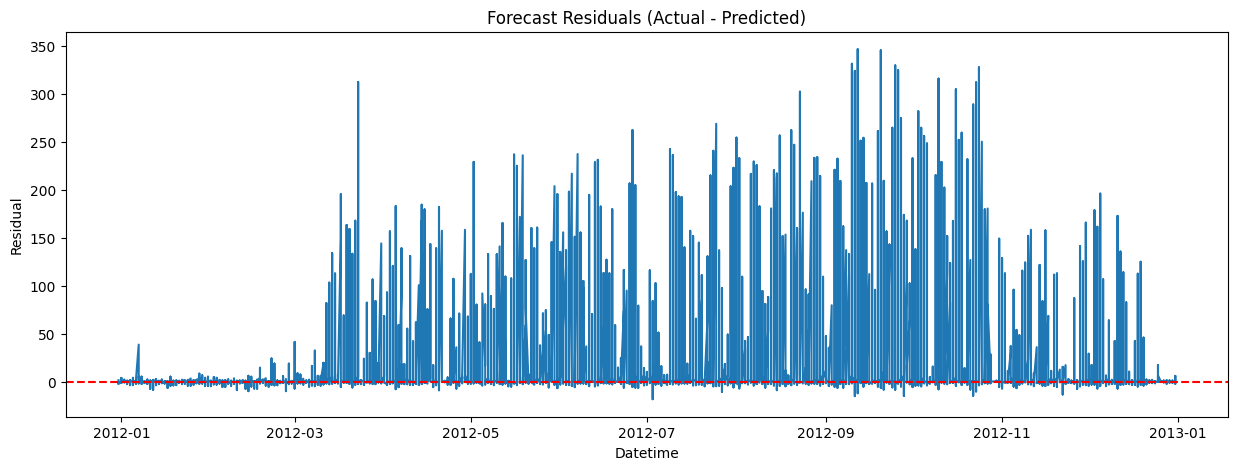

In [147]:
# Forecasting residuals
plt.figure(figsize=(15,5))

# Corrected the column name from 'Datetime' to 'dteday'
plt.plot(
    test_df["dteday"],
    residuals
)

plt.axhline(0, color='red', linestyle="--")

plt.title("Forecast Residuals (Actual - Predicted)")
plt.xlabel("Datetime")
plt.ylabel("Residual")

plt.show()

In [148]:
#Feature importance for GradientBoosting
importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": gbr_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
14,registered,0.8210475579
13,casual,0.1448279481
4,hr,0.0326538347
7,workingday,0.0005937416
10,atemp,0.0005935444
0,instant,0.0001271485
9,temp,0.0000646139
11,hum,0.0000348082
12,windspeed,0.0000250835
3,mnth,0.0000193436


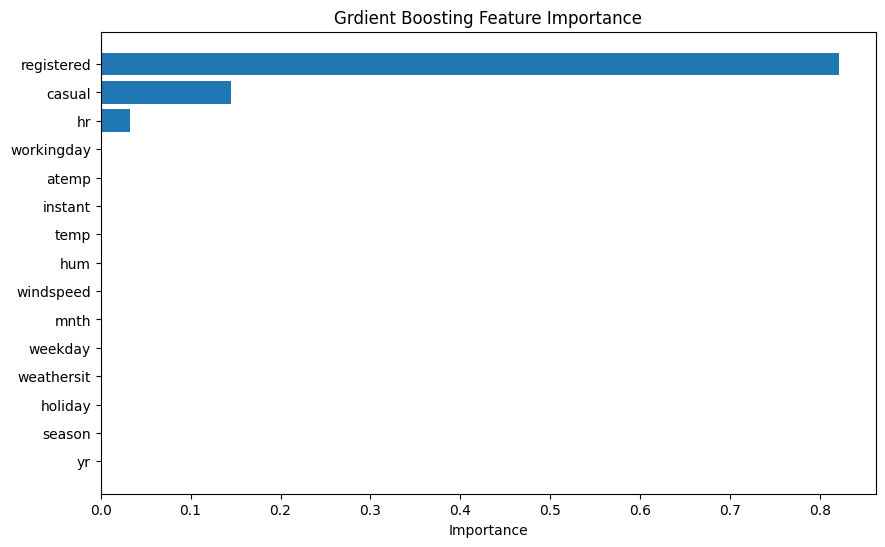

In [149]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Grdient Boosting Feature Importance")
plt.xlabel("Importance")

plt.show()

In [150]:
#30-day recursive forecast for Gradient Boosting
history_df = df.copy()

history_df = history_df.sort_values(
    "dteday"
).reset_index(drop=True)

In [151]:
#Create a function to calculate features for one timestamp :
def create_future_features(history):

    row = {}

    current_time = history["Datetime"].iloc[-1] + pd.Timedelta(hours=1)

    row["Hour"] = current_time.hour
    row["Day"] = current_time.day
    row["DayOfWeek"] = current_time.dayofweek
    row["Month"] = current_time.month
    row["Year"] = current_time.year
    row["IsWeekend"] = int(
        current_time.dayofweek in [5, 6]
    )

    row["IsHoliday"] = int(
        current_time.date() in holiday_dates
    )

    row["lag_1"] = history["PJMW_MW"].iloc[-1]
    row["lag_2"] = history["PJMW_MW"].iloc[-2]
    row["lag_3"] = history["PJMW_MW"].iloc[-3]

    row["lag_24"] = history["PJMW_MW"].iloc[-24]
    row["lag_48"] = history["PJMW_MW"].iloc[-48]
    row["lag_168"] = history["PJMW_MW"].iloc[-168]

    row["rolling_mean_24"] = (
        history["PJMW_MW"]
        .iloc[-24:]
        .mean()
    )

    row["rolling_mean_168"] = (
        history["PJMW_MW"]
        .iloc[-168:]
        .mean()
    )

    row["rolling_std_24"] = (
        history["PJMW_MW"]
        .iloc[-24:]
        .std()
    )

    return pd.DataFrame([row]), current_time

In [160]:
# Rebuild, train and predict the future demands correctly using the Gradient Boosting model
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor

# 1. Define model features excluding 'casual' and 'registered' to avoid data leaks during recursive prediction
forecast_features = [col for col in model_features if col not in ['casual', 'registered']]

# 2. Train the specific forecasting model
gbr_forecast_model = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.8,
    max_features=0.8,
    random_state=50
)
gbr_forecast_model.fit(X_train[forecast_features], y_train)

# 3. Initialize starting point from the bike sharing dataset
last_row = df.iloc[-1]
current_time = pd.to_datetime(last_row['dteday'])

future_predictions = []
for i in range(720):
    current_time += pd.Timedelta(hours=1)

    # Dynamically build features for the new step using bike share features
    new_row = pd.DataFrame([{
        'instant': int(last_row['instant'] + 1 + i),
        'season': last_row['season'],
        'yr': str(current_time.year),
        'mnth': str(current_time.month),
        'hr': current_time.hour,
        'holiday': last_row['holiday'],
        'weekday': current_time.weekday(),
        'workingday': 'Working Day' if current_time.weekday() < 5 else 'No work',
        'weathersit': last_row['weathersit'],
        'temp': last_row['temp'],
        'atemp': last_row['atemp'],
        'hum': last_row['hum'],
        'windspeed': last_row['windspeed']
    }])

    # Encode categorical features using fitted encoders
    for col in categorical_cols:
        le = encoders[col]
        val = str(new_row.loc[0, col])
        new_row[col] = le.transform([val])[0] if val in le.classes_ else le.transform([le.classes_[0]])[0]

    # Predict 'cnt' recursively
    prediction = max(0, gbr_forecast_model.predict(new_row[forecast_features])[0])

    future_predictions.append({
        "Datetime": current_time,
        "Predicted_cnt": prediction
    })

# Wrap predictions in a dataframe
future_forecast = pd.DataFrame(future_predictions)
print("Future forecasting complete!")
display(future_forecast.head())

Future forecasting complete!


,Datetime,Predicted_cnt
0,2012-12-31 01:00:00,15.0318496288
1,2012-12-31 02:00:00,6.9302448041
2,2012-12-31 03:00:00,7.3983354048
3,2012-12-31 04:00:00,3.1534098368
4,2012-12-31 05:00:00,10.4682431554


In [162]:
#Final DataFrame :
future_forecast = pd.DataFrame(
    future_predictions
)

future_forecast.head()

,Datetime,Predicted_cnt
0,2012-12-31 01:00:00,15.0318496288
1,2012-12-31 02:00:00,6.9302448041
2,2012-12-31 03:00:00,7.3983354048
3,2012-12-31 04:00:00,3.1534098368
4,2012-12-31 05:00:00,10.4682431554


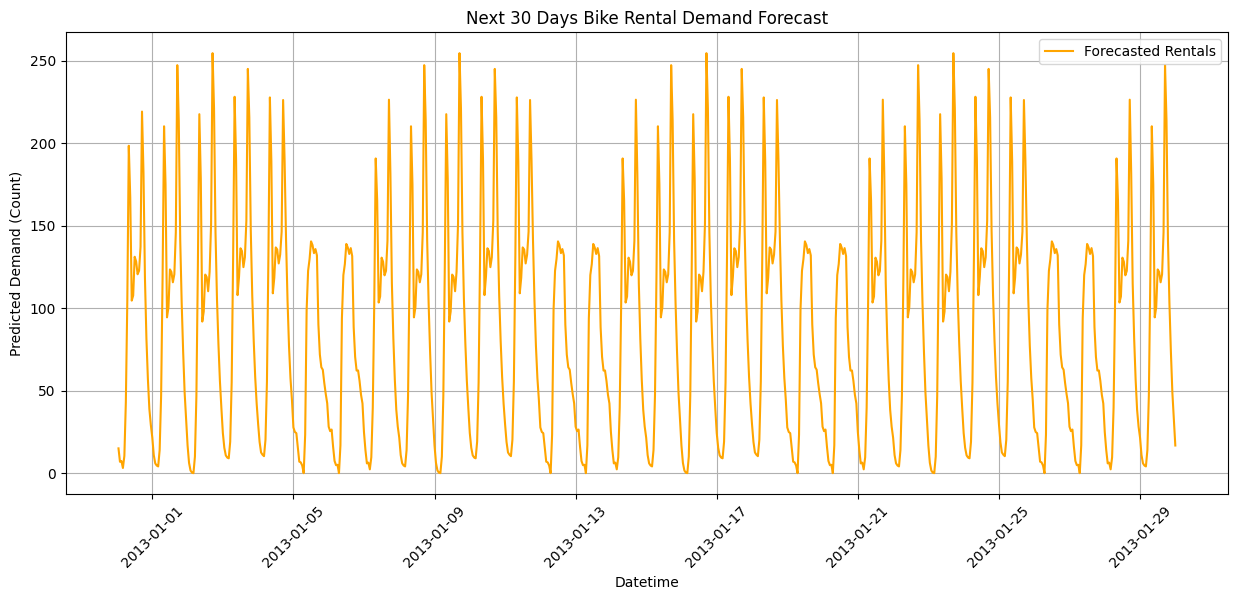

In [163]:
#Plot 30-day forecast
plt.figure(figsize=(15,6))

plt.plot(
    future_forecast["Datetime"],
    future_forecast["Predicted_cnt"],
    color="orange",
    label="Forecasted Rentals"
)

plt.title(
    "Next 30 Days Bike Rental Demand Forecast"
)

plt.xlabel("Datetime")
plt.ylabel("Predicted Demand (Count)")

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()

plt.show()

In [164]:
# Save forecast CSV
future_forecast.to_csv(
    "next_30_days_forecast.csv",
    index=False
)

In [165]:
# Saving the Best Model :
import joblib

joblib.dump(
    gbr_model,
    "gbr_model.pkl"
)

['gbr_model.pkl']

In [166]:
# Saving the feature list :
joblib.dump(
    feature_cols,
    "feature_columns.pkl"
)

['feature_columns.pkl']

In [167]:
# Save the comparison table:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

In [168]:
# Save the dataset information :
metadata = {
    "target": "PJMW_MW",
    "frequency": "Hourly",
    "forecast_horizon_days": 30,
    "forecast_horizon_hours": 720,
    "best_model": "XGBoost"
}

joblib.dump(
    metadata,
    "metadata.pkl"
)

['metadata.pkl']